# 1. Imports

In [1]:
import numpy as np
from python.sql_module import SQL
from python.read_module import ReadData
import pandas as pd
from pathlib import Path
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns

# 2. VARIABLES

In [2]:
_CONFIG_PATH = 'config.yaml'
_READER = ReadData(_CONFIG_PATH)

# 3. DATA

In [3]:
dim_calendar = _READER.read_data(table_name='gold_sku.dim_calendar')
fact_sales_agg_daily = _READER.read_data(table_name='gold_sku.fact_sales_agg_daily')
fact_sales_agg_daily_calendar = fact_sales_agg_daily.merge(
    dim_calendar,
    on='date'
)

fact_sales_agg_daily_calendar['year'] = [x.year for x in fact_sales_agg_daily_calendar['date']]

# 4. DATA QUALITY CHECKS

## 4.1 fact_sales_agg_daily

In [4]:
assert fact_sales_agg_daily.shape[0] == 1826
assert int(fact_sales_agg_daily['revenue'].sum()) == 644115980

# 5. FUNCTIONS 

## 5.1 Rolling Mean Function

In [5]:
def calculate_rolling_mean(
        df: pd.DataFrame,
        rolling_window: int,
        min_occurences: int,
        agg_column: str,
        group_by_column: str = None,
) -> pd.DataFrame:
    """
    Function that calculates the moving average over the specified rolling window and column.
    Params:

            df: DataFrame for which the column should be calculated.
            rolling_window: The window for which the moving average should be calculated.
            min_occurences: Minimal number of occurences in the rollig_window for the average to be calculated.
            agg_column: Name of the column for which the average should be calculated.
            group_by_column: Name of the column of the group for which the average should be calculated. Must be a datetime column.

    """
    if group_by_column:
        data_frame = pd.DataFrame(df.groupby(
            group_by_column
        )[agg_column].sum().rolling(rolling_window, min_occurences, center=True).mean()).rename(
            columns={agg_column:f'{agg_column}_{rolling_window}_d_avg'}
        )

        merged_frame = df.merge(
            data_frame,
            how='left',
            on=group_by_column
        )
        return merged_frame
        
    

## 5.2 Slope and Intercept

In [6]:
def calculate_slope_and_intercept(
        df: pd.DataFrame,
        x: str,
        y: str
):
    """
    Function that calculates the slope and intercept for given parameters.
    """
    y = df[y].dropna()
    locs = y.index
    x = df[x].loc[locs]
    return np.polyfit(x,y,1)

# 6. Data Viz

# 6.1 Whole level of the shop.

In [7]:
fact_sales_agg_daily = calculate_rolling_mean(fact_sales_agg_daily, 7, 7, 'revenue', group_by_column='date')
fact_sales_agg_daily = calculate_rolling_mean(fact_sales_agg_daily, 30, 30, 'revenue', group_by_column='date')
fact_sales_agg_daily = fact_sales_agg_daily.merge(
    dim_calendar[['date','days_since_start']],
    on='date'
)

In [8]:
slope_reg, intercept_reg = calculate_slope_and_intercept(
    fact_sales_agg_daily,
    x = 'days_since_start',
    y = 'revenue'
)

In [9]:
regular_line = slope_reg * fact_sales_agg_daily['days_since_start'] + intercept_reg

### 6.1.1 Daily Level.

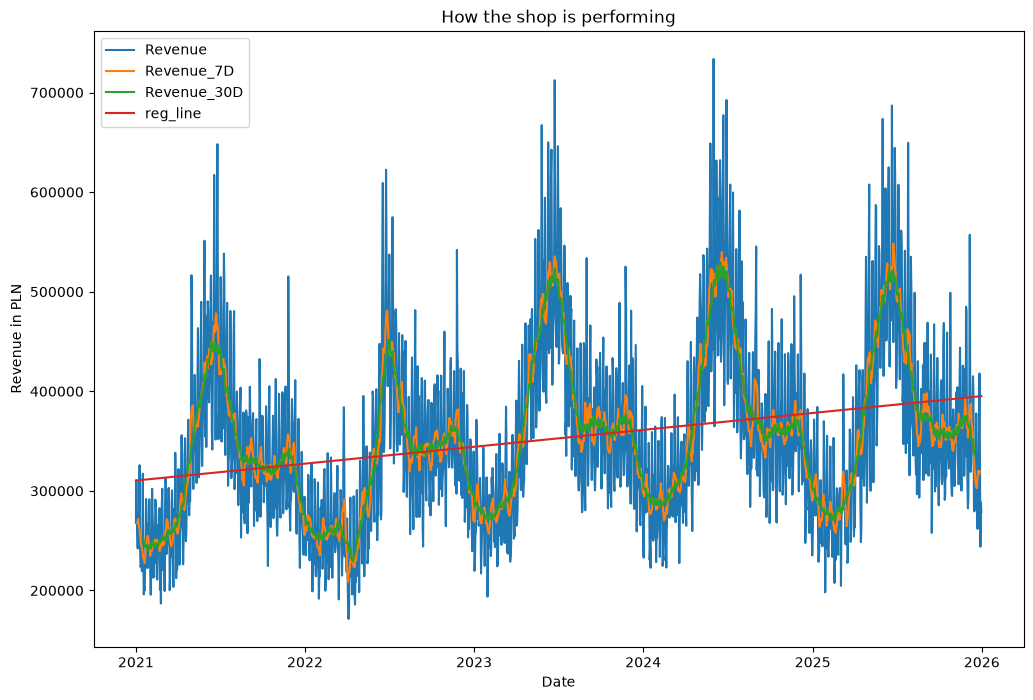

In [10]:
plt.figure(figsize=(12,8))
sns.lineplot(fact_sales_agg_daily, x='date', y='revenue', label = 'Revenue')
sns.lineplot(fact_sales_agg_daily, x='date', y = 'revenue_7_d_avg', label = 'Revenue_7D')
sns.lineplot(fact_sales_agg_daily, x='date', y = 'revenue_30_d_avg', label = 'Revenue_30D')
plt.plot(fact_sales_agg_daily['date'], regular_line, label = 'reg_line')
plt.legend();
plt.ylabel("Revenue in PLN");
plt.xlabel("Date");
plt.title("How the shop is performing");

### 6.1.2 Yearly Level

Text(0.5, 0, 'Year')

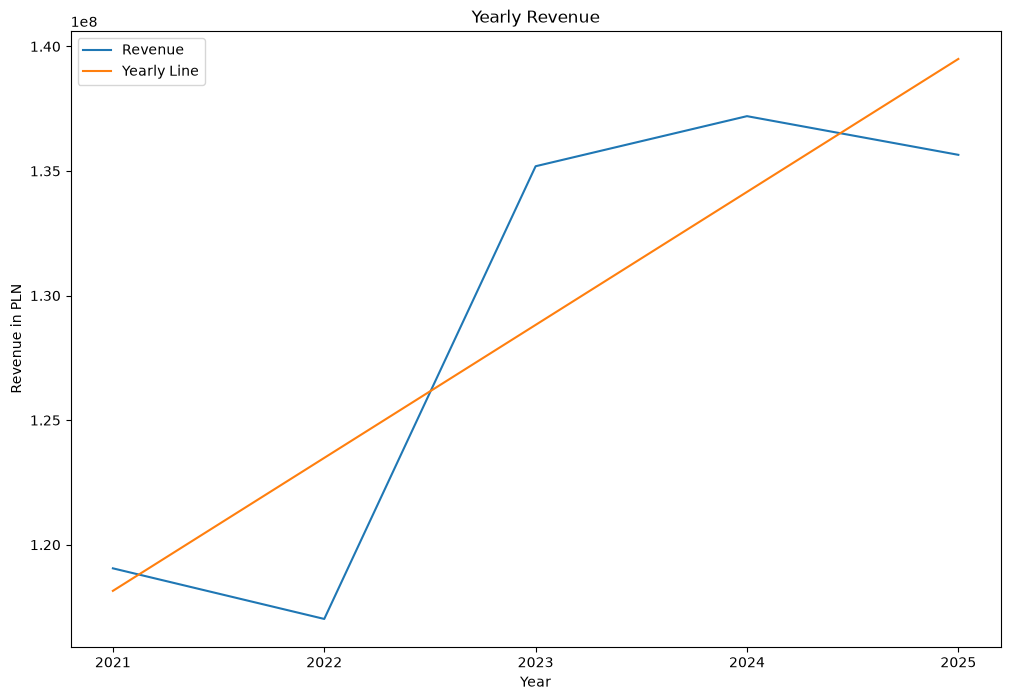

In [11]:
yearly_lvl = fact_sales_agg_daily_calendar.groupby(
    'year'
)['revenue'].sum().reset_index()

yearly_lvl['_len'] = np.arange(len(yearly_lvl))
yearly_slope, yearly_intercept = calculate_slope_and_intercept(
    yearly_lvl,
    x='_len',
    y = 'revenue'
)

yearly_line = yearly_slope * yearly_lvl['_len'] + yearly_intercept

plt.figure(figsize=(12,8))
ax = sns.lineplot(yearly_lvl, x='year', y='revenue', label = "Revenue")
plt.plot(yearly_lvl['year'], yearly_line, label="Yearly Line")
ax.set_xticks(np.array([2021, 2022 ,2023 ,2024, 2025]));
plt.legend();
plt.title("Yearly Revenue");
plt.ylabel("Revenue in PLN");
plt.xlabel("Year")

#### 6.1.2.1 Y/Y Level

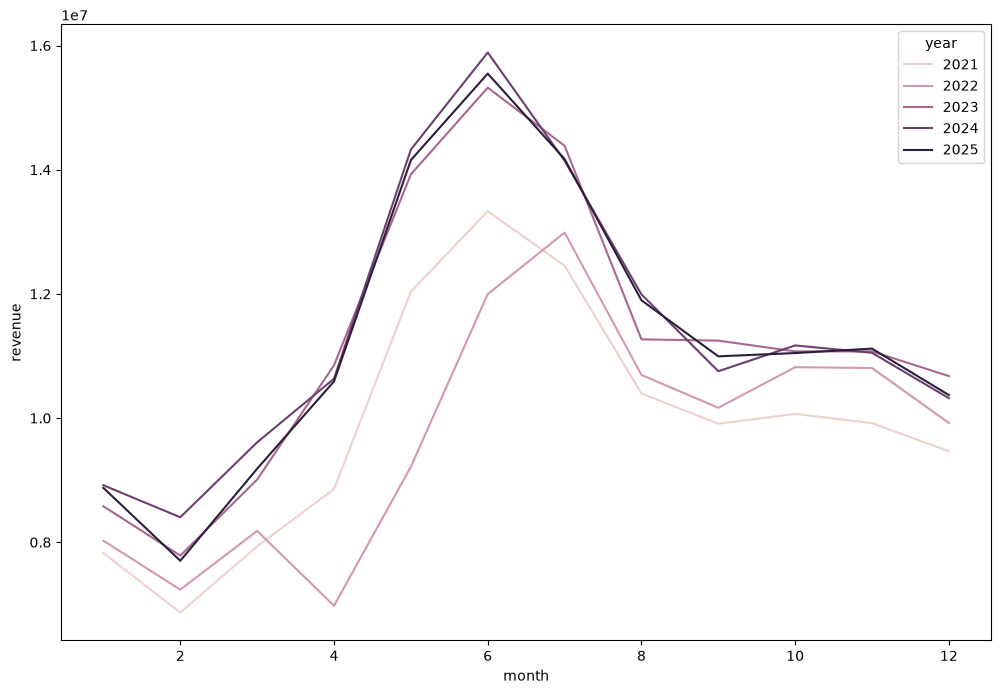

In [12]:
base = fact_sales_agg_daily_calendar.groupby(
    ['year','month']
)['revenue'].sum().reset_index()

plt.figure(figsize=(12,8))
sns.lineplot(base, x='month', y='revenue', hue='year');


## 6.1.3 Monthly Level

In [13]:
fact_sales_agg_daily_calendar['year_month'] = fact_sales_agg_daily_calendar['year'].astype(str) + fact_sales_agg_daily_calendar['month'].astype(str)
fact_sales_agg_daily_calendar['year_month'] = [datetime.strptime(str(x), "%Y%j").strftime("%Y-%m-%d") for x in fact_sales_agg_daily_calendar['year_month']]

In [14]:
fact_sales_agg_daily_calendar

,date,units_sold,revenue,stockout_attempts,stockout_units,days_since_start,quarter,month,iso_year,iso_day_of_week,...,is_special_day,commercial_event_name,next_special_day_in,days_since_last_special_day,is_payday_window,temperature_c_forecast,is_discount_period,discount_rate,year,year_month
0,2021-01-01,571.0,268031.22,1.0,1.0,1,1,1,2020,5.0,...,0,NaN,120.0,NaN,False,-1.5,0,0.0,2021,2021-01-01
1,2021-01-02,751.0,310675.78,2.0,2.0,2,1,1,2020,6.0,...,0,NaN,119.0,NaN,False,-4.9,1,0.2,2021,2021-01-01
2,2021-01-03,718.0,281026.97,4.0,7.0,3,1,1,2020,7.0,...,0,NaN,118.0,NaN,False,-0.4,1,0.2,2021,2021-01-01
3,2021-01-04,598.0,246080.98,3.0,6.0,4,1,1,2021,1.0,...,0,NaN,117.0,NaN,False,0.0,1,0.2,2021,2021-01-01
4,2021-01-05,623.0,242066.65,4.0,6.0,5,1,1,2021,2.0,...,0,NaN,116.0,NaN,False,-7.2,1,0.2,2021,2021-01-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1821,2025-12-27,902.0,417845.79,2.0,2.0,1822,4,12,2025,6.0,...,0,NaN,125.0,21.0,True,0.0,0,0.0,2025,2025-01-12
1822,2025-12-28,718.0,323640.47,2.0,4.0,1823,4,12,2025,7.0,...,0,NaN,124.0,22.0,False,1.1,0,0.0,2025,2025-01-12
1823,2025-12-29,533.0,243921.70,2.0,4.0,1824,4,12,2026,1.0,...,0,NaN,123.0,23.0,False,-0.4,0,0.0,2025,2025-01-12
1824,2025-12-30,575.0,288430.25,4.0,7.0,1825,4,12,2026,2.0,...,0,NaN,122.0,24.0,False,-4.3,0,0.0,2025,2025-01-12


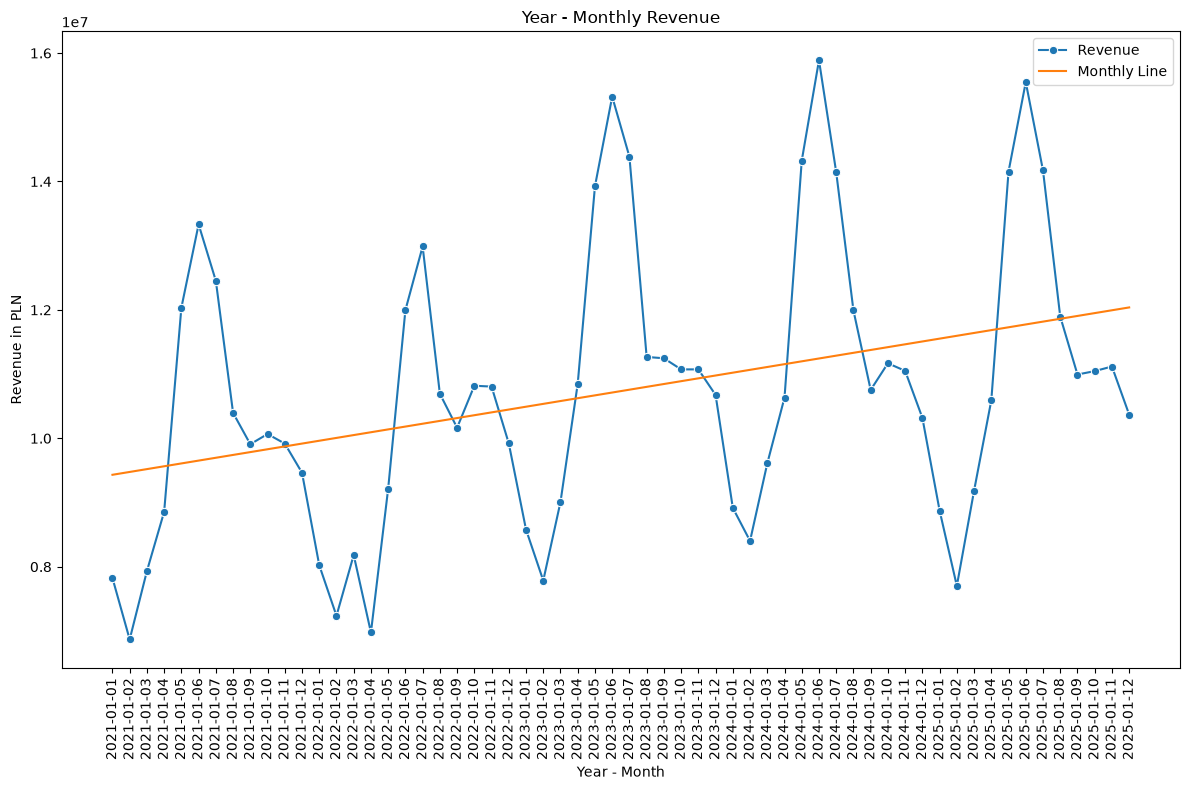

In [15]:
year_month_lvl = fact_sales_agg_daily_calendar.groupby(
    'year_month'
)['revenue'].sum().reset_index()

year_month_lvl['_len'] = np.arange(len(year_month_lvl))
year_month_slope, year_month_intercept = calculate_slope_and_intercept(
    year_month_lvl,
    x='_len',
    y = 'revenue'
)

monthly_line = year_month_slope * year_month_lvl['_len'] + year_month_intercept

plt.figure(figsize=(12,8))
ax = sns.lineplot(year_month_lvl, x='year_month', y='revenue', label = "Revenue", marker='o')
plt.plot(year_month_lvl['year_month'], monthly_line, label="Monthly Line")
plt.legend();
plt.title("Year - Monthly Revenue");
plt.ylabel("Revenue in PLN");
plt.xlabel("Year - Month")
plt.xticks(rotation = 90)
plt.tight_layout()

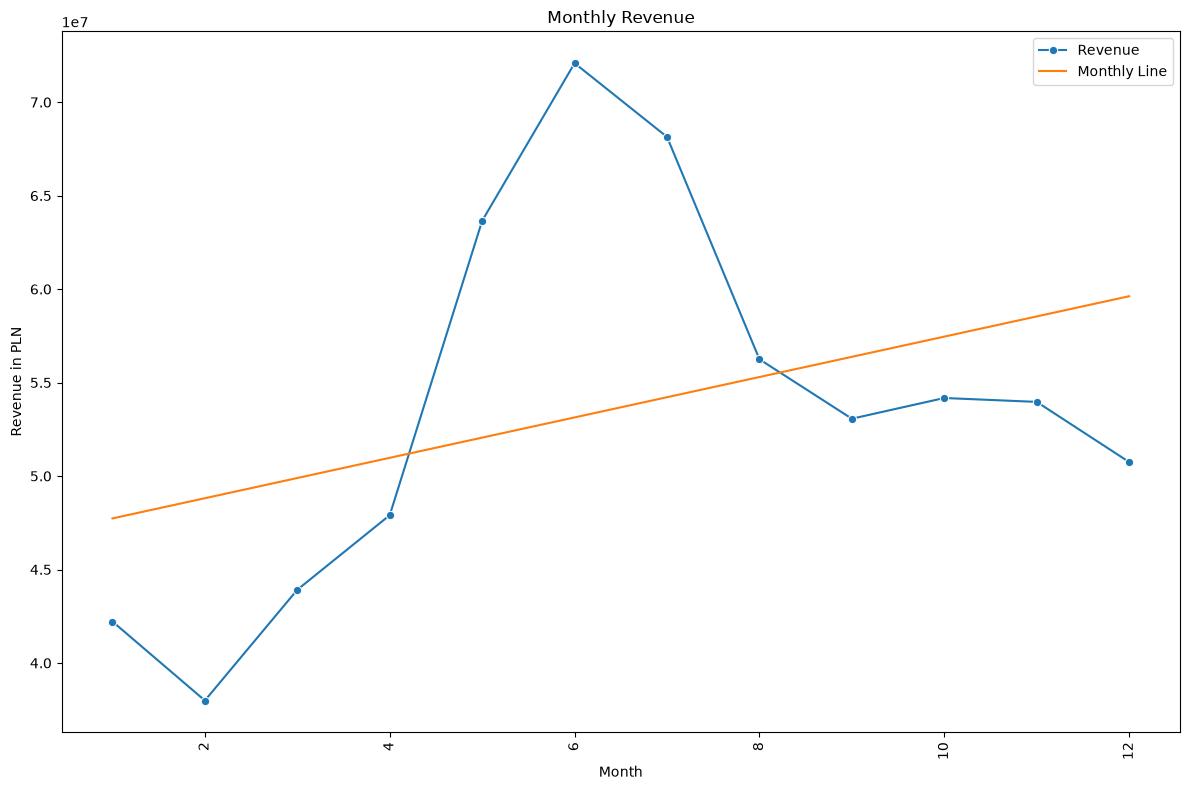

In [16]:
month_lvl = fact_sales_agg_daily_calendar.groupby(
    'month'
)['revenue'].sum().reset_index()

month_lvl['_len'] = np.arange(len(month_lvl))
month_slope, month_intercept = calculate_slope_and_intercept(
    month_lvl,
    x='_len',
    y = 'revenue'
)

monthly_line = month_slope * month_lvl['_len'] + month_intercept

plt.figure(figsize=(12,8))
ax = sns.lineplot(month_lvl, x='month', y='revenue', label = "Revenue", marker='o')
plt.plot(month_lvl['month'], monthly_line, label="Monthly Line")
plt.legend();
plt.title("Monthly Revenue");
plt.ylabel("Revenue in PLN");
plt.xlabel("Month")
plt.xticks(rotation = 90)
plt.tight_layout()

## 6.1.4 Weekly Level

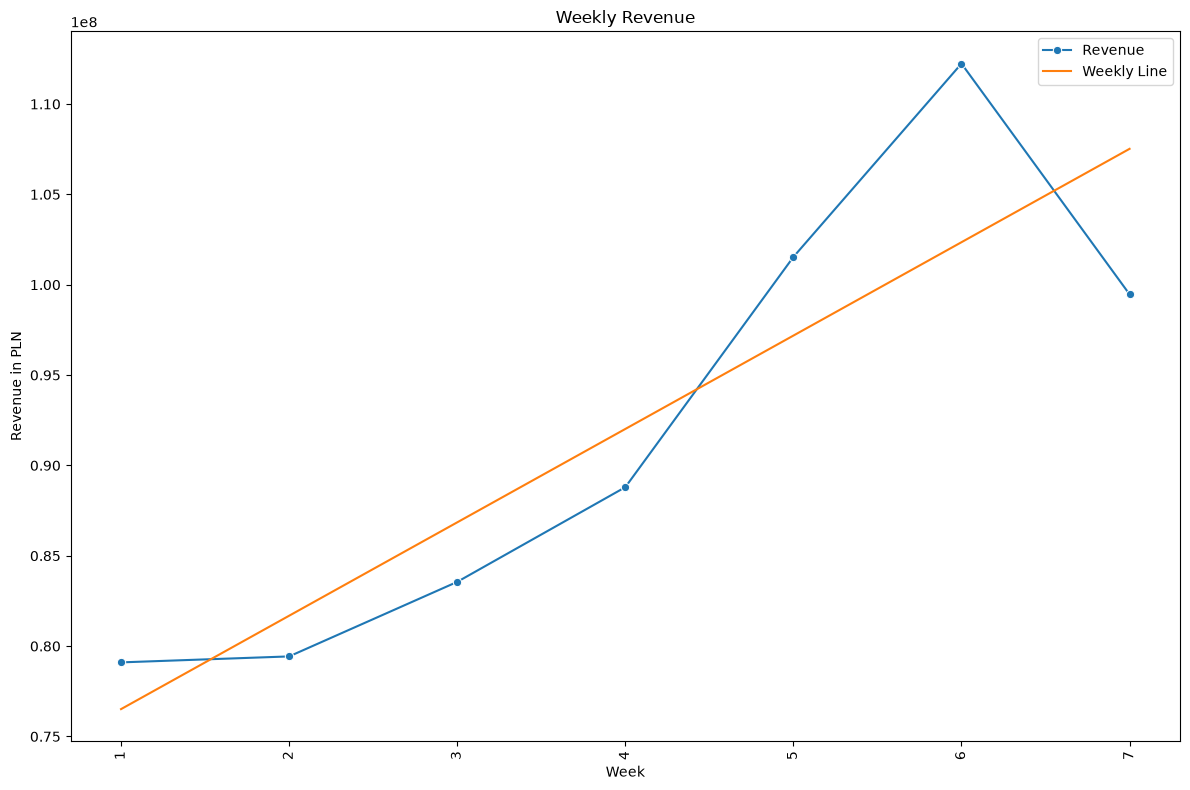

In [17]:
week_lvl = fact_sales_agg_daily_calendar.groupby(
    'iso_day_of_week'
)['revenue'].sum().reset_index()

week_lvl['_len'] = np.arange(len(week_lvl))
week_slope, week_intercept = calculate_slope_and_intercept(
    week_lvl,
    x='_len',
    y = 'revenue'
)

weekly_line = week_slope * week_lvl['_len'] + week_intercept

plt.figure(figsize=(12,8))
ax = sns.lineplot(week_lvl, x='iso_day_of_week', y='revenue', label = "Revenue", marker='o')
plt.plot(week_lvl['iso_day_of_week'], weekly_line, label="Weekly Line")
plt.legend();
plt.title("Weekly Revenue");
plt.ylabel("Revenue in PLN");
plt.xlabel("Week")
plt.xticks(rotation = 90)
plt.tight_layout()